# Retrieval-augmented generation, stage by stage

```
question -> clean -> retrieve (BM25) -> build context (labeled, budgeted) -> prompt -> generate -> check citations
```

**Questions explored**
1. What does each stage contribute, and what does the language model actually see?
2. When should the system refuse to answer? (questions the 1987 corpus cannot answer)
3. How many retrieved chunks are needed, and what does each extra chunk cost?
4. How can a wrong citation be detected automatically?

**Generation.** If `ANTHROPIC_API_KEY` is set (and the `anthropic` package installed), answers come from Claude.
Otherwise the notebook uses an **extractive** answerer that quotes the best-matching sentences with their source.
Everything else is identical, so the whole notebook runs offline. The saved outputs use the extractive answerer.

In [8]:
# %pip install torch transformers
# %pip install anthropic   # optional: generative answers instead of extractive ones, requires ANTHROPIC_API_KEY set in environment and billing plan

# Libraries and setup

In [9]:
import os
import re
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer

DATA_PATH = Path("classification_V1/reuters21578")
RANDOM_STATE = 42
CHUNK_SIZE, CHUNK_OVERLAP = 500, 50
TOP_K = 5                    # chunks retrieved per question
MAX_CONTEXT_CHARS = 2500     # budget for what the model sees
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)

## Corpus: parse, clean, chunk

In [10]:
def parse_sgm_file(filepath):
    with open(filepath, "r", encoding="latin-1") as f:
        soup = BeautifulSoup(f.read(), "html.parser")
    return [{"id": r.get("newid"),
             "date": r.date.text.strip()[:11] if r.date else "",
             "title": r.title.text.strip() if r.title else "",
             "body": r.body.text.strip() if r.body else ""}
            for r in soup.find_all("reuters")]

rows = []
for file in sorted(DATA_PATH.glob("*.sgm")):
    rows.extend(parse_sgm_file(file))
articles = pd.DataFrame(rows)
articles = articles[articles["body"].str.len() > 0].reset_index(drop=True)
articles["body"] = (articles["body"].str.replace(r"(?i)\s*reuter\W*$", "", regex=True).str.replace(r"\s+", " ", regex=True))
by_id = articles.set_index("id")

def chunk(text, size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    """Greedy sentence packing: never cut a sentence unless it alone exceeds `size`"""
    sentences = re.split(r"(?<=[.!?])\s+", text)
    pieces, current = [], ""
    for s in sentences:
        if current and len(current) + 1 + len(s) > size:
            pieces.append(current)
            current = current[-overlap:] + " " + s if overlap else s
        else:
            current = f"{current} {s}".strip()
    if current:
        pieces.append(current)
    return pieces

chunks = pd.DataFrame([{"chunk_id": f"{a.id}-{i}", "article_id": a.id, "text": piece} for a in articles.itertuples() for i, piece in enumerate(chunk(f"{a.title}. {a.body}"))])
print(f"{len(articles):,} articles -> {len(chunks):,} chunks")

19,043 articles -> 47,966 chunks


Here the headline is included in the first chunk: in a question-answering setting, the headline is useful
context, not a query.

# Stage 1–2: question cleaning and retrieval

BM25 (keyword ranking with saturating term frequency and length normalisation), built in a few lines.
The semantic-search notebook explores it, and its dense and hybrid alternatives, in depth.

In [11]:
class BM25:
    def __init__(self, texts, k1=1.5, b=0.75):
        self.vectorizer = CountVectorizer(token_pattern=r"(?u)\b\w+\b")
        tf = self.vectorizer.fit_transform(texts).tocoo().astype(np.float64)
        n = tf.shape[0]
        doc_len = np.bincount(tf.row, weights=tf.data, minlength=n)
        df = np.bincount(tf.col, minlength=tf.shape[1])
        self.idf = np.log(1 + (n - df + 0.5) / (df + 0.5))
        norm = k1 * (1 - b + b * doc_len[tf.row] / doc_len.mean())
        w = tf.data * (k1 + 1) / (tf.data + norm) * self.idf[tf.col]
        self.matrix = sparse.csr_matrix((w, (tf.row, tf.col)), shape=tf.shape)

    def query_terms(self, query):
        vocab = self.vectorizer.vocabulary_
        return [t for t in set(self.vectorizer.build_analyzer()(query)) if t in vocab]

    def scores(self, query):
        q = (self.vectorizer.transform([query]) > 0).astype(np.float64)
        return np.asarray(self.matrix @ q.T.toarray()).ravel()

bm25 = BM25(chunks["text"].tolist())

def clean_question(q):
    q = re.sub(r"\s+", " ", q).strip()
    if not q:
        raise ValueError("empty question")
    return q

def retrieve(question, k=TOP_K):
    scores = bm25.scores(clean_question(question))
    top = np.argsort(-scores)[:k]
    return chunks.iloc[top].assign(score=scores[top])

retrieve("Why did the Bundesbank keep its discount rate unchanged?")[["chunk_id", "score", "text"]]

,chunk_id,score,text
4475,1971-0,27.017552,BUNDESBANK LEAVES CREDIT POLICIES UNCHANGED. The Bundesbank left credit policies unchanged after today's r...
16094,7031-0,27.017552,BUNDESBANK LEAVES CREDIT POLICIES UNCHANGED. The Bundesbank left credit policies unchanged after today's r...
29008,12456-0,27.017552,BUNDESBANK LEAVES CREDIT POLICIES UNCHANGED. The Bundesbank left credit policies unchanged after today's r...
29044,12471-0,27.017552,BUNDESBANK LEAVES CREDIT POLICIES UNCHANGED. The Bundesbank left credit policies unchanged after today's r...
39919,17598-6,20.367490,redicts growth of just under two pct for the year. West Germany's trading partners are also likely to wait...


# Stage 3: building the context

The language model only knows what is in this string. 
Look first at what retrieval returned above: the top four results are the **same text**, filed on different dates. 
The Bundesbank council met every two weeks, and Reuters reused the wording whenever nothing changed. 
Passing all four would spend most of the budget repeating one fact.

Four decisions are made here:
- **label every passage:** with its source (`[Reuters-<id>]`, date, headline), otherwise the model has nothing to cite
- **one passage per article:** so one long story cannot crowd out the others
- **identical text is kept once:** with the other dates listed, so the information "this happened repeatedly" is preserved without repeating the passage
- **a character budget:** context costs money and latency, and very long contexts dilute attention

In [12]:
def build_context(retrieved, max_passages=TOP_K, max_chars=MAX_CONTEXT_CHARS):
    # `retrieved` is a ranked candidate list deeper than needed: duplicates are skipped, so filling `max_passages` slots takes more candidates than that
    passages, by_text, seen_articles, total = [], {}, set(), 0
    for row in retrieved.itertuples():
        if len(passages) == max_passages:
            break
        if row.article_id in seen_articles:
            continue
        seen_articles.add(row.article_id)
        meta = by_id.loc[row.article_id]
        key = re.sub(r"\W+", " ", row.text.lower()).strip()
        if key in by_text:                          # same wording already included: just record the date
            by_text[key]["reports"] += 1
            by_text[key]["also"].add(meta["date"].strip())
            continue
        size = len(row.text) + 80
        if total + size > max_chars and passages:
            break
        passage = {"id": row.article_id, "date": meta["date"].strip(), "title": meta["title"], "text": row.text, "also": set(), "reports": 1}
        passages.append(passage); by_text[key] = passage
        total += size
    blocks = []
    for p in passages:
        other_dates = sorted(p["also"] - {p["date"]}, key=lambda d: pd.to_datetime(d, format="%d-%b-%Y"))
        also = f" [same text in {p['reports']} reports; other dates: {', '.join(other_dates)}]" if p["reports"] > 1 else ""
        blocks.append(f"[Reuters-{p['id']}] ({p['date']}){also} {p['title']}\n{p['text']}")
    return "\n\n".join(blocks)[:max_chars], [p["id"] for p in passages]

context, sources = build_context(retrieve("Why did the Bundesbank keep its discount rate unchanged?", k=4 * TOP_K))
print(f"{len(context)} characters from articles {sources}\n")
print(context)

2236 characters from articles ['1971', '17598', '20748', '15444', '2251']

[Reuters-1971] (5-MAR-1987) [same text in 4 reports; other dates: 19-MAR-1987, 2-APR-1987] BUNDESBANK LEAVES CREDIT POLICIES UNCHANGED
BUNDESBANK LEAVES CREDIT POLICIES UNCHANGED. The Bundesbank left credit policies unchanged after today's regular meeting of its council, a spokesman said in answer to enquiries. The West German discount rate remains at 3.0 pct, and the Lombard emergency financing rate at 5.0 pct.

[Reuters-17598] (1-JUN-1987) BONN SEEN REJECTING NEW GROWTH MEASURES AT SUMMIT
redicts growth of just under two pct for the year. West Germany's trading partners are also likely to wait in in vain for any further pump-priming from the Bundesbank. Bundesbank vice-president Helmut Schlesinger made clear today the bank would keep interest rates down, but said there were no plans for a cut in the Bundesbank's key discount rate, which, at three pct, is near historical lows.

[Reuters-20748] (20-OCT-1987) NYS

# Stage 4: the prompt

The rules carry the main defences against hallucination: answer only from the context, cite the tag of each passage used, and say so when the context does not contain the answer. 
The corpus is from 1987, so the model is also told not to use its own, later knowledge.

In [13]:
SYSTEM_PROMPT = """You answer questions about Reuters news articles from 1987.
Rules:
- Use ONLY the passages provided. Do not use outside or later knowledge.
- After each claim, cite the tag of the passage it comes from, e.g. [Reuters-1234].
- If the passages do not contain the answer, reply exactly: "The articles provided do not answer this question."
- At most 4 sentences."""

def build_prompt(question, context):
    return f"Passages:\n{context}\n\nQuestion: {question}\nAnswer with citations:"

print(SYSTEM_PROMPT)

You answer questions about Reuters news articles from 1987.
Rules:
- Use ONLY the passages provided. Do not use outside or later knowledge.
- After each claim, cite the tag of the passage it comes from, e.g. [Reuters-1234].
- If the passages do not contain the answer, reply exactly: "The articles provided do not answer this question."
- At most 4 sentences.


# Stage 5: generation

`generate()` calls Claude when an API key is available. 
The offline fallback is **extractive**: it scores every sentence of the context by the IDF weight of the question terms it contains and returns the best ones, each with the tag of its passage. 
It cannot rephrase or combine facts, but it never states anything absent from the sources, which makes it a useful baseline to compare a generative answer against.

In [14]:
QWEN_MODEL = "Qwen/Qwen2.5-0.5B-Instruct" # "Qwen/Qwen2.5-1.5B-Instruct"       -0.5B (less RAM) / -3B (better answers)
_qwen = {}

def load_qwen():
    """
    Load once, reuse for every question (first call downloads ~3 GB)
    """
    if not _qwen:
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer
        device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
        tok = AutoTokenizer.from_pretrained(QWEN_MODEL)
        model = AutoModelForCausalLM.from_pretrained(QWEN_MODEL, torch_dtype="auto").to(device).eval()
        _qwen.update(tok=tok, model=model, device=device)
    return _qwen["tok"], _qwen["model"], _qwen["device"]

def generate_llm(question, context):
    try:
        import torch
        tok, model, device = load_qwen()
    except Exception as e:   # not installed / download failed -> extractive fallback
        raise RuntimeError(f"Qwen unavailable: {e}")

    messages = [{"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user", "content": build_prompt(question, context)}]
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok([text], return_tensors="pt").to(device)
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=300, do_sample=False)
    new_tokens = output[0][inputs["input_ids"].shape[1]:]   # drop the prompt, keep the answer
    return tok.decode(new_tokens, skip_special_tokens=True).strip()

In [15]:
LLM_MODEL = "claude-sonnet-4-6"

def generate_llm_claude(question, context):
    import anthropic   # raises ImportError if not installed -> extractive fallback
    if not os.environ.get("ANTHROPIC_API_KEY"):
        raise RuntimeError("ANTHROPIC_API_KEY not set")
    client = anthropic.Anthropic()
    response = client.messages.create(model=LLM_MODEL, max_tokens=300, temperature=0, system=SYSTEM_PROMPT, messages=[{"role": "user", "content": build_prompt(question, context)}])
    return "".join(b.text for b in response.content if b.type == "text")

In [16]:
def generate_extractive(question, context, n_sentences=2):
    terms = set(bm25.query_terms(question))
    idf = dict(zip(bm25.vectorizer.get_feature_names_out(), bm25.idf))
    candidates = []
    for block in context.split("\n\n"):
        tag = re.match(r"\[Reuters-\d+\]", block).group(0)
        body = block.split("\n", 1)[1]
        for sentence in re.split(r"(?<=[.!?])\s+", body):
            words = set(bm25.vectorizer.build_analyzer()(sentence))
            score = sum(idf[t] for t in terms & words)
            candidates.append((score, sentence.strip(), tag))
    best = sorted(candidates, key=lambda c: -c[0])[:n_sentences]
    if not best or best[0][0] == 0:
        return "The articles provided do not answer this question."
    return " ".join(f"{s} {tag}" for _, s, tag in best)

In [21]:
def generate(question, context, use_llm=True):
    if use_llm:
        try:
            return generate_llm(question, context), "llm"
        #   return generate_llm_claude(question, context), "llm"   # uncomment to use Claude instead of Qwen (needs ANTHROPIC_API_KEY set and billing plan)
        except (ImportError, RuntimeError) as e:
            return generate_extractive(question, context), "extractive"
    else:
        return generate_extractive(question, context), "extractive"

# Stage 6: checking the citations

Every `[Reuters-<id>]` in the answer is compared with the passages that were actually in the context. 
A citation to an article the model never saw is certainly wrong: a cheap, automatic hallucination signal. 
(It does not prove that a *valid* citation supports the sentence; that needs a judged evaluation.)

In [19]:
def check_citations(answer, context_sources):
    cited = list(dict.fromkeys(re.findall(r"\[Reuters-(\d+)\]", answer)))
    return {"cited": cited,
            "supported": [c for c in cited if c in context_sources],
            "not_in_context": [c for c in cited if c not in context_sources]}

check_citations("Rates were left unchanged [Reuters-5160], as expected [Reuters-99999].", ["5160", "5176"])

{'cited': ['5160', '99999'],
 'supported': ['5160'],
 'not_in_context': ['99999']}

# The full pipeline

In [ ]:
def ask(question, k=TOP_K, verbose=True, use_llm=True):
    retrieved = retrieve(question, 4 * k)        # deeper candidate list: duplicates get skipped
    context, sources = build_context(retrieved, max_passages=k)
    answer, mode = generate(question, context, use_llm=use_llm)
    check = check_citations(answer, sources)
    if verbose:
        print(f"Q: {question}\n")
        print(textwrap.fill(answer, 110))
        print(f"\n[{mode}] sources in context: {sources}  |  cited: {check['cited']}  |  not in context: {check['not_in_context'] or 'none'}")
    return {"answer": answer, "sources": sources, "top_score": float(retrieved["score"].iloc[0]), **check}

_ = ask("Why did the Bundesbank keep its discount rate unchanged?", use_llm=True)

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Q: Why did the Bundesbank keep its discount rate unchanged?

The Bundesbank kept its discount rate unchanged because the West German discount rate remained at 3.0%.

[llm] sources in context: ['1971', '17598', '20748', '15444', '2251']  |  cited: []  |  not in context: none


In [23]:
_ = ask("Why did the Bundesbank keep its discount rate unchanged?", use_llm=False)

Q: Why did the Bundesbank keep its discount rate unchanged?

Bundesbank vice-president Helmut Schlesinger made clear today the bank would keep interest rates down, but
said there were no plans for a cut in the Bundesbank's key discount rate, which, at three pct, is near
historical lows. [Reuters-17598] "We need additional time to understand why Baker did not accept our
proposal." Kistler also said that the law suit filed by Baker "was not a factor" in the board's decision to
keep its merger proposal on the table. [Reuters-2251]

[extractive] sources in context: ['1971', '17598', '20748', '15444', '2251']  |  cited: ['17598', '2251']  |  not in context: none


no capture of the real reason, the answer to the "why", explained to it did not changed because it remained constant, but doesn't explain why it remained constant, which is the real question. The extractive answerer does not hallucinate, but it cannot combine facts to answer the "why" either. Yet, the answer captured tell that the bank would like the interest rate to remain low, something the very little LLM there cannot capture.

In [24]:
_ = ask("What did Chrysler pay for American Motors?", use_llm=True)

Q: What did Chrysler pay for American Motors?

Chrysler paid $15,966 million for American Motors.

[llm] sources in context: ['4582', '4986', '6554', '3139', '9046']  |  cited: []  |  not in context: none


In [25]:
_ = ask("What did Chrysler pay for American Motors?", use_llm=False)

Q: What did Chrysler pay for American Motors?

American Motors did not release further details of Chrysler's plans for maintaining or changing American
Motors' current strategy other than to quote Cappy as saying, "we will try to keep you informed as
developments warrant." [Reuters-4582] Other terms of the accord call for Chrysler to give Renault a 200 mln
dlr, eight pct note due in 10 years and 35 mln dlrs in cash for its American Motors interest. [Reuters-6554]

[extractive] sources in context: ['4582', '4986', '6554', '3139', '9046']  |  cited: ['4582', '6554']  |  not in context: none


In reuters file new_id=19415 : two billion dlrs is the amount Chrystler paid for the aquisition of American Motors, which is the answer to the question "What did Chrysler pay for American Motors?".
6554 used in context rightly speak of 1.5 billion dlrs, I must assume that I did really tried to find the right answer comparing dates etc, the idea is that it's roughly the right answer, but not the exact one.
Both generation are far from it : 
- the small LLM respond to the good question, but with a wrong answer : $15,966 found in new_id=4986 corresponding to a price increase of its cars. Better model may be the solution
- the extractive answerer doesn't mention anything related to this deal, even if the context does capture the right documents in which you can find the infos 

In [26]:
_ = ask("What happened to tanker traffic in the Gulf?", use_llm=True)

Q: What happened to tanker traffic in the Gulf?

A tanker hit a mine in the Gulf on October 19th.

[llm] sources in context: ['17462', '21197', '20034', '5866']  |  cited: []  |  not in context: none


In [27]:
_ = ask("What happened to tanker traffic in the Gulf?", use_llm=False)

Q: What happened to tanker traffic in the Gulf?

spokesman, Francois Giuliani, said Perez de Cuellar had no comment on the attack, taken in response to Iranian
action against an American-owned tanker last week, but was trying to find out "what actually happened." Calls
to Iran's U.N. [Reuters-21197] Alexander Ivanov, head of the Gulf desk at the Soviet Foreign Ministry, told
Al-Rai al-Aam newspaper Moscow "will answer back with force and violence if Iran attempts to attack any Soviet
ship or tanker in the Gulf." A Soviet tanker hit a mine in the Gulf last month. [Reuters-17462]

[extractive] sources in context: ['17462', '21197', '20034', '5866']  |  cited: ['21197', '17462']  |  not in context: none


Here both find the right answwer, llm is way more direct and factual while the extractive answerer tell more about general context and the wanted information come as the last info shared.

Read the answers critically: an extractive answer can quote a sentence that matches the question's words without answering it. 
That is a retrieval-and-ranking limit, and the reason generation and reranking exist.
(context has been checked to contain the right informations before hand to really check only the generation part, not the retrieval part)

# A fair test set

The next two experiments use 1987 headlines as questions. 
But every headline is *inside* its own first chunk, so retrieval would find it verbatim and look far better than it is. 
For these measurements only, a second index is built from article **bodies** (no headlines), as in the semantic-search notebook.

In [28]:
body_chunks = pd.DataFrame([{"chunk_id": f"{a.id}-{i}", "article_id": a.id, "text": piece} for a in articles.itertuples() for i, piece in enumerate(chunk(a.body))])
bm25_body = BM25(body_chunks["text"].tolist())
print(f"body-only index: {len(body_chunks):,} chunks")

body-only index: 46,078 chunks


# When should the system refuse?

The corpus covers February to October 1987. 
A question about anything else should get "no answer", not the closest-looking 1987 article. 
BM25 always returns *something*: the question is whether its best score is high enough to trust.

Raw BM25 scores grow with the number of query terms, so the comparison uses **top score / sum of IDF of the query terms**: roughly, how much of the question's informative vocabulary the best chunk matches. 
It can exceed 1, because BM25 rewards a term that occurs several times by up to a factor k1 + 1 = 2.5.

In [29]:
def match_strength(question, index=bm25):
    terms = index.query_terms(question)
    if not terms:
        return 0.0
    vocab = index.vectorizer.vocabulary_
    return float(index.scores(question).max() / sum(index.idf[vocab[t]] for t in terms))

in_domain = articles.sample(150, random_state=RANDOM_STATE)["title"].str.lower().tolist()
out_of_domain = [
    "what was tesla's revenue in 2023", "who won the 2018 football world cup",
    "how does the bitcoin halving affect miners", "what did the european central bank decide in 2022",
    "when did the iphone launch", "how many employees does amazon have",
    "what is the population of nigeria today", "who is the current president of france",
    "what caused the 2008 financial crisis", "how do covid vaccines work",
    "what is the price of a netflix subscription", "when was the euro introduced",
    "which company makes the playstation 5", "what are nvidia's latest gpus",
    "how did brexit affect the pound", "what is chatgpt", "who founded spacex",
    "what is the interest rate on us treasury bills in 2024",
    "how many people use instagram", "what did the federal reserve do in 2020",
]
strengths = pd.DataFrame({
    "match strength": [match_strength(q, bm25_body) for q in in_domain + out_of_domain],
    "question type": ["1987 headline"] * len(in_domain) + ["outside the corpus"] * len(out_of_domain),
})
strengths.groupby("question type")["match strength"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
question type,,,,,,,,
1987 headline,150.0,0.862,0.212,0.438,0.702,0.825,1.007,1.409
outside the corpus,20.0,0.807,0.283,0.372,0.581,0.841,0.942,1.604


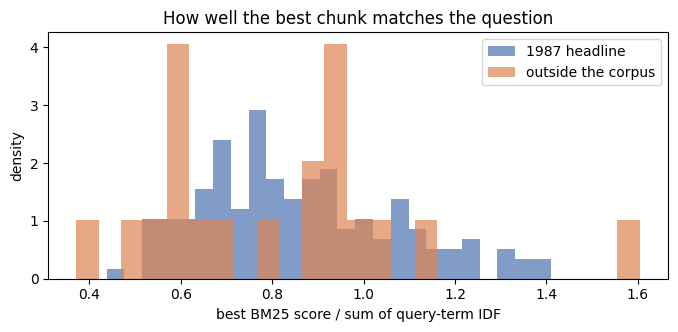

In [30]:
plt.figure(figsize=(8, 3.2))
for kind, color in [("1987 headline", "#4C72B0"), ("outside the corpus", "#DD8452")]:
    plt.hist(strengths[strengths["question type"] == kind]["match strength"], bins=25, alpha=0.7, label=kind, color=color, density=True)
plt.xlabel("best BM25 score / sum of query-term IDF"); plt.ylabel("density"); plt.legend()
plt.title("How well the best chunk matches the question");

In [31]:
def refusal_rates(threshold):
    s = strengths.set_index("question type")["match strength"]
    return {"threshold": threshold,
            "1987 questions refused (wrongly)": float((s.loc["1987 headline"] < threshold).mean()),
            "outside questions refused (correctly)": float((s.loc["outside the corpus"] < threshold).mean())}

pd.DataFrame([refusal_rates(t) for t in [0.7, 0.8, 0.9, 1.0, 1.1, 1.2]]).round(2)

,threshold,1987 questions refused (wrongly),outside questions refused (correctly)
0,0.7,0.25,0.40
1,0.8,0.45,0.50
2,0.9,0.61,0.60
3,1.0,0.75,0.80
4,1.1,0.85,0.90
5,1.2,0.92,0.95


**The score cannot separate the two groups:** At every threshold, the share of 1987 questions refused wrongly is about the same as the share of modern questions refused correctly: the threshold is no better than refusing at random. 
The reason is visible in the questions themselves: "what did the federal reserve do in 2020" or "how did brexit affect the pound" share strong, specific words ("federal reserve", "pound") with 1987 currency news, so the best 1987 chunk matches them as well as a real 1987 question.

Lexical match measures *whether the words appear*, not *whether the question is answerable*.
Two cheaper signals are worth testing: words the corpus has never seen (bitcoin, covid) and years after 1987.

In [32]:
YEAR = re.compile(r"\b(1[89]\d\d|20\d\d)\b")
corpus_vocab = set(bm25.vectorizer.vocabulary_)
STOP = {"what", "who", "how", "when", "which", "is", "the", "of", "does", "did", "do", "a", "in", "on", "to", "are", "today", "many", "current", "latest"}

def out_of_scope_signals(question):
    words = [w for w in re.findall(r"[a-z]+", question.lower()) if w not in STOP]
    unknown = [w for w in words if w not in corpus_vocab]
    later_year = any(int(y) > 1987 for y in YEAR.findall(question))
    return {"unknown words": unknown, "year after 1987": later_year, "flagged": bool(unknown) or later_year}

signals = pd.DataFrame([{"question": q, **out_of_scope_signals(q)} for q in out_of_domain])
print(f"flagged: {signals['flagged'].mean():.0%} of the 20 out-of-scope questions: {np.mean([out_of_scope_signals(q)['flagged'] for q in in_domain]):.0%} of the 150 1987 headlines")
signals

flagged: 80% of the 20 out-of-scope questions: 1% of the 150 1987 headlines


,question,unknown words,year after 1987,flagged
0,what was tesla's revenue in 2023,[tesla],True,True
1,who won the 2018 football world cup,[],True,True
2,how does the bitcoin halving affect miners,[bitcoin],False,True
3,what did the european central bank decide in 2022,[],True,True
4,when did the iphone launch,[iphone],False,True
5,how many employees does amazon have,[],False,False
6,what is the population of nigeria today,[],False,False
7,who is the current president of france,[],False,False
8,what caused the 2008 financial crisis,[],True,True
9,how do covid vaccines work,[covid],False,True


The two rules catch most out-of-scope questions, and each flag has a readable reason, which a score threshold does not give. 
They are not a complete solution:
- they cannot catch a modern question written in 1987 vocabulary ("who is the current president of france")
- the false-refusal rate on 1987 questions is understated here, because headlines only contain words that are, by construction, in the corpus vocabulary: real user questions would contain unseen words more often.

So refusal needs several layers: cheap rules like these, a relevance model (a cross-encoder scores question–passage pairs far better than word overlap), and the prompt rule telling the model to say when the
passages do not answer.

Caveats: headlines are written in the vocabulary of their article, and 20 out-of-scope questions is a small sample. 
The conclusion below is nevertheless clear-cut.

# How many chunks does the model need?

If the right passage is not retrieved, no language model can fix the answer. 
Using headlines as questions and their own article as the target, how often is the target among the top *k* chunks, and how much context does that cost?

In [33]:
targets = articles.sample(300, random_state=RANDOM_STATE + 1)
ranks = []
for row in targets.itertuples():
    question = row.title.lower()
    scores = bm25_body.scores(question)
    order = np.argsort(-scores)[:50]
    hit = np.flatnonzero(body_chunks["article_id"].to_numpy()[order] == row.id)
    ranks.append(hit[0] + 1 if len(hit) else np.inf)
ranks = np.array(ranks)

avg_chunk = body_chunks["text"].str.len().mean()
budget = pd.DataFrame([{"k (chunks in context)": k, "target retrieved": float(np.mean(ranks <= k)), "approx. context chars": int(k * avg_chunk)} for k in [1, 2, 3, 5, 10, 20, 50]])
budget.round(3)

,k (chunks in context),target retrieved,approx. context chars
0,1,0.543,362
1,2,0.647,724
2,3,0.700,1087
3,5,0.733,1812
4,10,0.777,3624
5,20,0.810,7249
6,50,0.827,18123


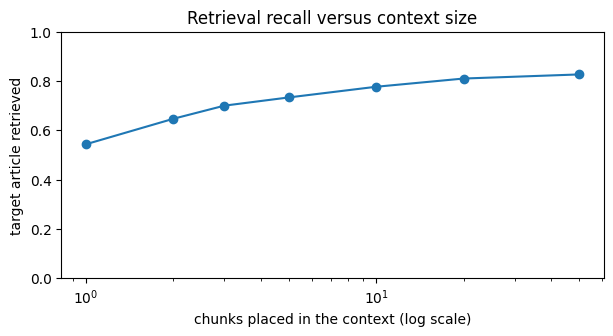

In [34]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(budget["k (chunks in context)"], budget["target retrieved"], marker="o")
ax.set_xscale("log"); ax.set_ylim(0, 1)
ax.set_xlabel("chunks placed in the context (log scale)"); ax.set_ylabel("target article retrieved")
ax.set_title("Retrieval recall versus context size");

The best chunk is the right one only about half the time: five chunks bring it to roughly three quarters, and going from 10 to 50 chunks adds a few points for five times the context. 
Where the curve flattens, around 80%, is the **retrieval ceiling**: for about one question in five, the evidence never reaches the model, whatever its quality. 
Improving the retriever (hybrid search, reranking) raises that ceiling; a better language model does not.

# Takeaways

- **The context builder is where citations become possible**: passages must carry their source id, or every citation the model writes is invented.
- **Refusal cannot rely on keyword-match scores**: out-of-scope questions matched 1987 articles as well as real 1987 questions did. 
Unseen words and later years flag most of them with a stated reason: a relevance model and the prompt's "say so" rule are still needed for the rest.
- **Retrieval sets the ceiling**: here roughly one question in five never gets its evidence into the context, and no amount of generation quality fixes that. 
Extra chunks show diminishing returns for a linear cost.
- **Duplicated sources are common in news** (the same Bundesbank wording filed on several dates): collapsing them frees context for distinct evidence, and recording the dates keeps the fact that the event repeated.
- **Citation checks are cheap and catch a real failure** (citing unseen articles), but do not prove that a cited passage supports the claim.
- **An extractive baseline is worth keeping**: it never invents facts, and comparing it with the generative answer shows what generation actually adds.